# EDA comparativa — Fake.br-Corpus × FakeTrue.Br

Compara os dois datasets analisados nos notebooks 01 e 02, para responder:

- Eles medem a mesma coisa? (época, fontes, natureza do rótulo `true`)
- Os padrões que separam fake de true são os mesmos nos dois?
- O mesmo conteúdo aparece nos dois (quase-duplicatas)?
- Dá para juntá-los numa base só, ou um modelo aprenderia "de qual dataset veio" em vez de "é fake"?
- Um modelo treinado num funciona no outro (generalização)?

Datasets esperados em `../data/raw/` (links simbólicos para os clones locais). Definições das métricas: [glossário](../references/glossario-metricas.md).

In [1]:
import re
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline

FAKEBR_DIR = Path("../data/raw/Fake.br-Corpus")
FAKETRUE_CSV = Path("../data/raw/FakeTrue.Br/FakeTrueBr_corpus.csv")
SEED = 42

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)

## 1. Carregamento num esquema comum

Cada texto vira uma linha com as mesmas colunas nos dois datasets:

| Coluna | Fake.br-Corpus | FakeTrue.Br |
|---|---|---|
| `dataset` | `fakebr` | `faketrue` |
| `grupo` | número do par | link do texto verdadeiro (a mesma checagem se repete em vários pares) |
| `texto` | `full_texts` | coluna `fake` / `true` |
| `texto_normalizado` | `size_normalized_texts` | truncado por par (mesma regra, reconstruída) |
| `dominio` | do link nos metadados | do link no CSV |
| `ano` | da data nos metadados | da URL (só existe no lado `true`) |

**Fake.br:** as versões `full_texts` e `size_normalized_texts` estão alinhadas por número de arquivo em 3.598 dos 3.600 pares (as poucas diferenças de conteúdo são de codificação, como "1º" × "1o"). Os ids 586 e 1607 só existem na versão completa, e os ids 697 e 1468 só na normalizada (textos quase vazios, só com título). Esses 4 pares são descartados aqui.

In [2]:
def ler_pasta(pasta: Path) -> dict:
    return {int(p.stem): p.read_text(encoding="utf-8", errors="ignore") for p in pasta.glob("*.txt")}


def ano_da_data(bruta: str) -> float:
    m = re.search(r"\b(19\d{2}|20\d{2})\b", bruta or "")
    return float(m.group(1)) if m else np.nan


linhas, fora = [], set()
for classe in ["fake", "true"]:
    completos = ler_pasta(FAKEBR_DIR / "full_texts" / classe)
    normalizados = ler_pasta(FAKEBR_DIR / "size_normalized_texts" / classe)
    fora |= set(completos) ^ set(normalizados)
    for arquivo in (FAKEBR_DIR / "full_texts" / f"{classe}-meta-information").glob("*-meta.txt"):
        id_ = int(arquivo.stem.split("-")[0])
        if id_ not in completos or id_ not in normalizados:
            continue
        meta = [l.strip() for l in arquivo.read_text(encoding="utf-8", errors="ignore").splitlines()]
        linhas.append({
            "dataset": "fakebr", "classe": classe, "grupo": f"fakebr-{id_}",
            "texto": completos[id_], "texto_normalizado": normalizados[id_],
            "link": meta[1], "ano": ano_da_data(meta[3]),
        })
fakebr = pd.DataFrame(linhas)
print(f"Fake.br: ids fora da interseção das duas versões (descartados): {sorted(fora)}")

bruto = pd.read_csv(FAKETRUE_CSV)
palavras_fake = bruto["fake"].str.split()
palavras_true = bruto["true"].str.split()
tamanho_par = [min(len(a), len(b)) for a, b in zip(palavras_fake, palavras_true)]
faketrue = pd.concat([
    pd.DataFrame({"dataset": "faketrue", "classe": "fake", "grupo": bruto["link_t"],
                  "texto": bruto["fake"].str.strip(), "link": bruto["link_f"],
                  "texto_normalizado": [" ".join(p[:n]) for p, n in zip(palavras_fake, tamanho_par)]}),
    pd.DataFrame({"dataset": "faketrue", "classe": "true", "grupo": bruto["link_t"],
                  "texto": bruto["true"].str.strip(), "link": bruto["link_t"],
                  "texto_normalizado": [" ".join(p[:n]) for p, n in zip(palavras_true, tamanho_par)]}),
], ignore_index=True)
faketrue["ano"] = faketrue["link"].str.extract(r"/(20\d{2})/")[0].astype(float)

df = pd.concat([fakebr, faketrue], ignore_index=True)
df["dominio"] = df["link"].str.extract(r"https?://(?:www\d?\.)?([^/]+)")[0]
df["n_palavras"] = df["texto"].str.split().str.len()
print(df.groupby(["dataset", "classe"]).size().unstack())

Fake.br: ids fora da interseção das duas versões (descartados): [586, 697, 1468, 1607]


classe    fake  true
dataset             
fakebr    3598  3598
faketrue  1791  1791


## 2. Harmonização do texto

Os datasets chegaram com pré-processamentos diferentes (notebook 02, seção 2.1): o FakeTrue.Br está em minúsculas, sem hífens, com anos sem o zero e parte das fakes sem acento. Comparar os textos como estão faria qualquer modelo separar os datasets por esses detalhes.

Por isso, todas as análises a partir daqui usam uma versão **harmonizada**, igual para os dois:

| Passo | Exemplo |
|---|---|
| minúsculas | "Lula" → "lula" |
| sem acentos | "não" → "nao" |
| hífen entre palavras removido (como no FakeTrue.Br) | "ex-presidente" → "expresidente" |
| números removidos | "2018", "218" → (vazio) |
| **boilerplate** removido: frases que se repetem (após canonicalização) em 20+ textos da base combinada | rodapés do G1, do Boatos.org, da UOL |
| nomes de veículos e checadores removidos | g1, globo, estadão, boatos.org, fato ou fake... |
| marcadores de tempo removidos | "nesta", "quartafeira", meses |

O que **fica**: vocabulário em geral, nomes de pessoas e eventos, pontuação, e a linguagem de checagem (analisada à parte na seção 7).

In [3]:
def sem_acentos(texto: str) -> str:
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")


def frases(texto: str) -> list:
    partes = re.split(r"[.!?]\s+|\s+,\s+,\s*|\n+", texto)
    return [p.strip(" ,") for p in partes if len(p.strip(" ,")) > 20]


def canonica(frase: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[\W_]+", " ", frase)).strip()


def pre_harmonizar(texto: str) -> str:
    t = sem_acentos(texto.lower())
    t = re.sub(r"(\w)-(\w)", r"\1\2", t)
    return re.sub(r"\d+", " ", t)


base = df["texto"].map(pre_harmonizar)
LIMIAR_BOILERPLATE = 20
docs_por_grupo, variantes = Counter(), defaultdict(set)
for texto in base:
    fs = set(frases(texto))
    for g in {canonica(f) for f in fs}:
        docs_por_grupo[g] += 1
    for f in fs:
        variantes[canonica(f)].add(f)
BOILERPLATE = sorted({v for g, n in docs_por_grupo.items() if n >= LIMIAR_BOILERPLATE for v in variantes[g]},
                     key=len, reverse=True)
print(f"Variações de boilerplate removidas: {len(BOILERPLATE)}")

RODAPES = [
    r"ps\.?:?\s*esse artigo (e|foi) uma sugestao[^.]*\.",
    r"se voce quiser sugerir um tema (ao|para o) boatos\.org.*?(\s\d*-?\s*\.|$)",
    r"clique nos links bit\.ly[^.]*\.?",
    r"(video:? )?veja como identificar (se )?uma mensagem (e )?falsa",
]
PADRAO_FONTES = (
    r"\b(g1|globo(\.com)?|rede globo|tv globo|uol|folha( de s\.? ?paulo)?|piaui|estadao|reuters|"
    r"agencia (brasil|estado)|diario do brasil|diariodobrasil|antagonista|afolhabrasil|thejornalbrasil|"
    r"ceticismo politico|boatos(\.org)?|fato ou fake|afp|checamos|lupa|aos fatos|comprova|efarsas)\b"
)
PADRAO_TEMPO = (
    r"\b(nest[ae]|ontem|hoje|segunda|terca|quarta|quinta|sexta|sabado|domingo|\w*feira|"
    r"janeiro|fevereiro|marco|abril|maio|junho|julho|agosto|setembro|outubro|novembro|dezembro)\b"
)


def harmonizar(texto: str) -> str:
    t = pre_harmonizar(texto)
    for frase in BOILERPLATE:
        t = t.replace(frase, " ")
    for padrao in RODAPES:
        t = re.sub(padrao, " ", t)
    t = re.sub(PADRAO_FONTES, " ", t)
    t = re.sub(PADRAO_TEMPO, " ", t)
    return re.sub(r"\s+", " ", t).strip()


df["texto_harm"] = df["texto"].map(harmonizar)
df["texto_normalizado_harm"] = df["texto_normalizado"].map(harmonizar)
exemplo = df[(df["dataset"] == "fakebr") & df["texto"].str.contains("ex-")].iloc[0]
print("\nANTES :", re.sub(r"\s+", " ", exemplo["texto"])[:250])
print("DEPOIS:", exemplo["texto_harm"][:250])

Variações de boilerplate removidas: 28



ANTES : Discurso de Lula em 2009: "É preciso construir uma Nova Ordem Mundial". Veja como Lula, o PT e o Foro de São Paulo fecharam um acordo com os Illuminati para dominar a América do Sul. (Amanda Nunes Brückner) O PT é braço dos Illuminati aqui no Brasil 
DEPOIS: discurso de lula em : "e preciso construir uma nova ordem mundial". veja como lula, o pt e o foro de sao paulo fecharam um acordo com os illuminati para dominar a america do sul. (amanda nunes bruckner) o pt e braco dos illuminati aqui no brasil tal 


**Como ler:** o exemplo mostra o mesmo texto antes e depois da harmonização. A lista de boilerplate é calculada na base combinada, então pega rodapés dos dois datasets. **Limitação:** a remoção é por lista e por padrão — pode apagar demais ("Rio de Janeiro" perde "janeiro") ou de menos.

## 3. Visão lado a lado

                 textos  grupos  mediana_palavras  ano_min  ano_mediano  ano_max  pct_com_ano
dataset  classe                                                                              
fakebr   fake      3598    3598             157.5   2012.0       2016.0   2018.0         1.00
         true      3598    3598             918.5   2009.0       2017.0   2018.0         1.00
faketrue fake      1791    1344             109.0      NaN          NaN      NaN         0.00
         true      1791    1344             377.0   2007.0       2021.0   2023.0         0.94

Top domínios por dataset e classe:
  fakebr/fake: diariodobrasil.org (93%), afolhabrasil.com.br (5%), thejornalbrasil.com.br (2%)
  fakebr/true: g1.globo.com (64%), politica.estadao.com.br (21%), internacional.estadao.com.br (3%)
  faketrue/fake: boatos.org (100%)
  faketrue/true: g1.globo.com (86%), noticias.uol.com.br (4%), piaui.folha.uol.com.br (4%)


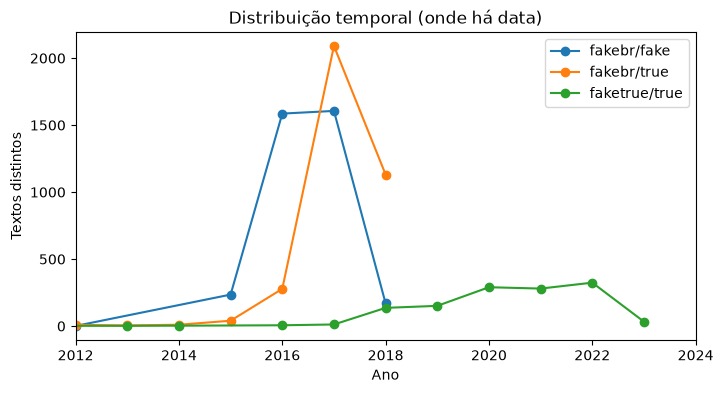

In [4]:
resumo = df.groupby(["dataset", "classe"]).agg(
    textos=("texto", "size"),
    grupos=("grupo", "nunique"),
    mediana_palavras=("n_palavras", "median"),
    ano_min=("ano", "min"),
    ano_mediano=("ano", "median"),
    ano_max=("ano", "max"),
    pct_com_ano=("ano", lambda s: s.notna().mean()),
)
print(resumo.round(2))

print("\nTop domínios por dataset e classe:")
for (dataset, classe), sub in df.groupby(["dataset", "classe"]):
    top = sub["dominio"].value_counts(normalize=True).head(3).round(3)
    print(f"  {dataset}/{classe}: " + ", ".join(f"{d} ({p:.0%})" for d, p in top.items()))

fig, ax = plt.subplots(figsize=(8, 4))
for (dataset, classe), sub in df.dropna(subset=["ano"]).groupby(["dataset", "classe"]):
    contagem = sub.drop_duplicates("link")["ano"].value_counts().sort_index()
    ax.plot(contagem.index, contagem.values, marker="o", label=f"{dataset}/{classe}")
ax.set_xlim(2012, 2024)
ax.set_xlabel("Ano")
ax.set_ylabel("Textos distintos")
ax.set_title("Distribuição temporal (onde há data)")
ax.legend()
plt.show()

**Como ler:** `grupos` < `textos` indica reuso (a mesma checagem em vários pares no FakeTrue.Br). `pct_com_ano` mostra de onde a data existe — as fakes do FakeTrue.Br não têm data. Linhas do gráfico em épocas diferentes = nomes e eventos de cada época viram pista de origem.

## 4. Os padrões que separam fake de true são os mesmos?

Para cada dataset, calcula os 100 termos mais associados a cada classe (chi² sobre presença/ausência, no texto normalizado por tamanho e harmonizado) e mede quantos coincidem entre os dois datasets.

**Índice de Jaccard** = termos em comum ÷ termos no total das duas listas. 1 = listas idênticas; 0 = nenhum termo em comum.

In [5]:
def termos_discriminativos(textos: pd.Series, classes: pd.Series, top_n: int = 100) -> tuple:
    vetorizador = CountVectorizer(binary=True, min_df=5)
    X = vetorizador.fit_transform(textos)
    e_fake = (classes == "fake").to_numpy()
    scores, _ = chi2(X, e_fake)
    tabela = pd.DataFrame({
        "chi2": scores,
        "prop_fake": np.asarray(X[e_fake].mean(axis=0)).ravel(),
        "prop_true": np.asarray(X[~e_fake].mean(axis=0)).ravel(),
    }, index=vetorizador.get_feature_names_out())
    top_fake = tabela[tabela.prop_fake > tabela.prop_true].nlargest(top_n, "chi2")
    top_true = tabela[tabela.prop_true > tabela.prop_fake].nlargest(top_n, "chi2")
    return top_fake, top_true


try:
    import nltk

    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords

    STOPWORDS = {sem_acentos(p) for p in stopwords.words("portuguese")}
except Exception:
    STOPWORDS = set()


termos = {}
for dataset, sub in df.groupby("dataset"):
    textos = sub["texto_normalizado_harm"].map(lambda t: " ".join(w for w in t.split() if w not in STOPWORDS))
    termos[dataset] = termos_discriminativos(textos, sub["classe"])

for i, classe in enumerate(["fake", "true"]):
    a, b = set(termos["fakebr"][i].index), set(termos["faketrue"][i].index)
    comuns = a & b
    print(f"{classe.upper()}: Jaccard = {len(comuns) / len(a | b):.3f} ({len(comuns)} termos em comum de 100)")
    print("   em comum:", ", ".join(sorted(comuns)[:25]) or "—")
    print("   só Fake.br (top 10):", ", ".join([t for t in termos["fakebr"][i].index if t not in comuns][:10]))
    print("   só FakeTrue.Br (top 10):", ", ".join([t for t in termos["faketrue"][i].index if t not in comuns][:10]))
    print()

/home/feliperodr/ResIA/Challenge1/experimentos/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/feliperodr/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


FAKE: Jaccard = 0.117 (21 termos em comum de 100)
   em comum: ai, algo, atraves, bem, cara, coisa, comunista, deus, imediatamente, midia, porque, povo, pra, reais, sabe, toda, todo, tudo, urgente, vamos, vou
   só Fake.br (top 10): lavajato, dilma, disse, tambem, video, materia, jornalista, podera, redes, site
   só FakeTrue.Br (top 10): todos, org, agora, span, vai, ta, amigos, compartilhe, atencao, olha

TRUE: Jaccard = 0.081 (15 termos em comum de 100)
   em comum: afirma, desde, desta, diz, entanto, estados, federal, inacio, luiz, ministerio, nega, segundo, silva, sobre, tribunal
   só Fake.br (top 10): regiao, regional, integra, eldorado, fm, supremo, play, ano, ouvir, degravacao
   só FakeTrue.Br (top 10): redes, sociais, circula, mensagem, falsa, texto, mostra, mensagens, legenda, circulam



**Como ler:** Jaccard baixo = cada dataset tem seus próprios "marcadores" de fake e de true, e o que um modelo aprende num dificilmente vale no outro. Os termos **em comum** são os candidatos a sinal mais geral de desinformação. Ver [glossário](../references/glossario-metricas.md).

## 5. Quase-duplicatas entre os datasets

O mesmo boato pode ter sido coletado nos dois. Se isso acontece e os datasets forem combinados ou usados como treino/teste um do outro, o modelo "reconhece" o texto em vez de generalizar.

Para cada texto do FakeTrue.Br, busca o texto mais parecido do Fake.br-Corpus pela **similaridade de cosseno** entre os vetores TF-IDF (0 = nada em comum; 1 = mesmas palavras nas mesmas proporções).

**Padrão de mercado:** em bases grandes (milhões de textos) usa-se **MinHash + LSH** (ex.: biblioteca `datasketch`), que aproxima essa busca com pouca memória. Com ~11 mil textos, a comparação exata cabe na memória e é mais precisa, então é a usada aqui.

In [6]:
vetorizador = TfidfVectorizer(min_df=2, sublinear_tf=True)
X_todos = vetorizador.fit_transform(df["texto_harm"])
e_fakebr = (df["dataset"] == "fakebr").to_numpy()
X_fb, X_ft = X_todos[e_fakebr], X_todos[~e_fakebr]
df_fb, df_ft = df[e_fakebr].reset_index(drop=True), df[~e_fakebr].reset_index(drop=True)

vizinhos = NearestNeighbors(n_neighbors=1, metric="cosine", algorithm="brute").fit(X_fb)
distancia, indice = vizinhos.kneighbors(X_ft)
df_ft["similaridade_max"] = 1 - distancia.ravel()
df_ft["vizinho_fakebr"] = indice.ravel()

faixas = pd.cut(df_ft["similaridade_max"], [0, 0.3, 0.5, 0.7, 0.9, 1.0001],
                labels=["< 0,3", "0,3–0,5", "0,5–0,7", "0,7–0,9", "≥ 0,9"], right=False)
print("Similaridade do texto do FakeTrue.Br com o texto mais parecido do Fake.br:")
print(pd.crosstab(faixas, df_ft["classe"]))

print("\nPares mais parecidos:")
for _, linha in df_ft.nlargest(3, "similaridade_max").iterrows():
    viz = df_fb.loc[linha["vizinho_fakebr"]]
    print(f"\n[sim = {linha['similaridade_max']:.2f}] FakeTrue.Br/{linha['classe']}  ×  Fake.br/{viz['classe']}")
    print("  FakeTrue.Br:", linha["texto_harm"][:200])
    print("  Fake.br    :", viz["texto_harm"][:200])

Similaridade do texto do FakeTrue.Br com o texto mais parecido do Fake.br:
classe            fake  true
similaridade_max            
< 0,3             1764  1755
0,3–0,5             18    28
0,5–0,7              6     2
0,7–0,9              1     1
≥ 0,9                2     5

Pares mais parecidos:

[sim = 1.00] FakeTrue.Br/true  ×  Fake.br/true
  FakeTrue.Br: ja e noite quando uma multidao de venezuelanos faz uma enorme fila para receber um pao e um copo de leite na praca simon bolivar, em boa vista. famintos, eles devoram o alimento doado e depois se deit
  Fake.br    : fuga da fome: como a chegada de mil venezuelanos transformou boa vista. nas contas da prefeitura, imigrantes representam mais de % da populacao da cidade. o reflexo se ve nas ruas: pracas ocupadas, ab

[sim = 0.99] FakeTrue.Br/fake  ×  Fake.br/fake
  FakeTrue.Br: <i>roberto carlos afirma: o lugar de lula e na presidencia do brasil, e inaceitavel o que esta acontecendo. nas ultimas semanas do programa do jo o convidad

**Como ler:** a maioria abaixo de 0,3 = conteúdos diferentes. Faixas acima de 0,7 = provável mesmo texto (ou a mesma história) nos dois datasets; esses casos precisam ser removidos antes de combinar os datasets ou de usar um como teste do outro. Termos no [glossário](../references/glossario-metricas.md).

## 6. Dá para distinguir de qual dataset veio o texto?

**Teste de classificabilidade por origem:** um classificador tenta prever `fakebr` × `faketrue`, ignorando se o texto é fake ou true. Todos os textos são cortados nas primeiras 60 palavras harmonizadas, para o tamanho não entregar a origem.

- Se ele acerta muito, os datasets têm "sotaques" próprios. Juntá-los sem cuidado faz um modelo de fake/true aprender a origem como atalho — especialmente porque a proporção fake/true e a natureza do `true` são diferentes em cada um.
- O teste é feito também **dentro de cada classe** (só fakes; só trues), para ver onde está a diferença.

Validação cruzada agrupada por `grupo`.

In [7]:
def primeiras_palavras(texto: str, n: int = 60) -> str:
    return " ".join(texto.split()[:n])


def modelo_texto():
    return make_pipeline(TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True),
                         LogisticRegression(max_iter=2000))


def avaliar_cv(textos: pd.Series, alvo: pd.Series, grupos: pd.Series) -> pd.Series:
    resultado = cross_validate(modelo_texto(), textos, alvo, groups=grupos, cv=GroupKFold(n_splits=5),
                               scoring=["accuracy", "f1"])
    return pd.Series({"acuracia": resultado["test_accuracy"].mean(), "f1": resultado["test_f1"].mean()})


df["texto_60"] = df["texto_harm"].map(primeiras_palavras)
e_faketrue = (df["dataset"] == "faketrue").astype(int)

origem = {"todos os textos": avaliar_cv(df["texto_60"], e_faketrue, df["grupo"])}
for classe in ["fake", "true"]:
    sub = df["classe"] == classe
    origem[f"só {classe}"] = avaliar_cv(df.loc[sub, "texto_60"], e_faketrue[sub], df.loc[sub, "grupo"])
print("Prever a ORIGEM (fakebr × faketrue):")
print(pd.DataFrame(origem).T.round(3))

Prever a ORIGEM (fakebr × faketrue):
                 acuracia     f1
todos os textos     0.883  0.796
só fake             0.881  0.794
só true             0.906  0.839


**Como ler:** as bases têm tamanhos diferentes (7.200 × 3.582 textos), então o chute de referência é **0,67** (responder sempre `fakebr`), não 0,5 — compare também o F1 (classe positiva = `faketrue`). Perto de 1,0 = cada dataset é facilmente reconhecível, mesmo depois da harmonização. "Só true" alto é esperado: o `true` do Fake.br é notícia comum, o do FakeTrue.Br é checagem.

## 7. Generalização cruzada: treinar num, testar no outro

Um classificador fake × true é treinado **inteiro** num dataset e testado **inteiro** no outro. Para comparação, a mesma configuração é avaliada dentro de cada dataset com validação cruzada agrupada.

Representações:

- **texto (60 palavras)**: harmonizado e cortado, sem o atalho de tamanho;
- **texto sem linguagem de checagem**: igual, removendo também "circula", "falso", "boato"... (a marca do `true` do FakeTrue.Br);
- **só comprimento**: log do número de palavras do texto completo.

`prop_prevista_fake` = fração dos textos do teste classificados como fake. O esperado seria 0,5; valores extremos indicam que o modelo "desistiu" e chuta quase tudo numa classe só.

In [8]:
PADRAO_CHECAGEM = (
    r"\b(circulam?|fake|fals[oa]s?|checage[mn]s?|checad[oa]s?|montage[mn]s?|enganos[oa]s?|"
    r"boatos?|verifica\w*|desinforma\w*)\b|\be \. ,"
)
df["texto_60_sem_checagem"] = df["texto_harm"].map(
    lambda t: primeiras_palavras(re.sub(r"\s+", " ", re.sub(PADRAO_CHECAGEM, " ", t))))
df["log_palavras"] = np.log1p(df["n_palavras"])


def treinar_e_testar(coluna: str, treino: str, teste: str) -> dict:
    a, b = df[df["dataset"] == treino], df[df["dataset"] == teste]
    if coluna == "log_palavras":
        modelo = LogisticRegression(max_iter=2000)
        X_a, X_b = a[[coluna]], b[[coluna]]
    else:
        modelo = modelo_texto()
        X_a, X_b = a[coluna], b[coluna]
    y_a, y_b = (a["classe"] == "fake").astype(int), (b["classe"] == "fake").astype(int)
    previsto = modelo.fit(X_a, y_a).predict(X_b)
    return {"acuracia": accuracy_score(y_b, previsto), "f1": f1_score(y_b, previsto),
            "prop_prevista_fake": previsto.mean()}


def dentro_do_dataset(coluna: str, dataset: str) -> dict:
    sub = df[df["dataset"] == dataset]
    alvo = (sub["classe"] == "fake").astype(int)
    if coluna == "log_palavras":
        r = cross_validate(LogisticRegression(max_iter=2000), sub[[coluna]], alvo, groups=sub["grupo"],
                           cv=GroupKFold(n_splits=5), scoring=["accuracy", "f1"])
    else:
        r = cross_validate(modelo_texto(), sub[coluna], alvo, groups=sub["grupo"],
                           cv=GroupKFold(n_splits=5), scoring=["accuracy", "f1"])
    return {"acuracia": r["test_accuracy"].mean(), "f1": r["test_f1"].mean(), "prop_prevista_fake": np.nan}


linhas = []
for coluna, nome in [("texto_60", "texto (60 palavras)"),
                     ("texto_60_sem_checagem", "texto sem linguagem de checagem"),
                     ("log_palavras", "só comprimento")]:
    for treino, teste in [("fakebr", "fakebr"), ("faketrue", "faketrue"), ("fakebr", "faketrue"), ("faketrue", "fakebr")]:
        r = dentro_do_dataset(coluna, treino) if treino == teste else treinar_e_testar(coluna, treino, teste)
        linhas.append({"representacao": nome, "treino": treino, "teste": teste, **r})
generalizacao = pd.DataFrame(linhas).set_index(["representacao", "treino", "teste"])
print(generalizacao.round(3))

                                                   acuracia     f1  prop_prevista_fake
representacao                   treino   teste                                        
texto (60 palavras)             fakebr   fakebr       0.877  0.876                 NaN
                                faketrue faketrue     0.902  0.907                 NaN
                                fakebr   faketrue     0.574  0.636               0.672
                                faketrue fakebr       0.613  0.684               0.723
texto sem linguagem de checagem fakebr   fakebr       0.877  0.875                 NaN
                                faketrue faketrue     0.897  0.902                 NaN
                                fakebr   faketrue     0.583  0.641               0.663
                                faketrue fakebr       0.619  0.681               0.695
só comprimento                  fakebr   fakebr       0.941  0.941                 NaN
                                faketrue fa

**Como ler:**

- `treino = teste` (validação cruzada dentro do dataset) é a referência: o quanto o modelo acerta **no mesmo tipo de dado**.
- `treino ≠ teste` é o teste de generalização. Queda grande em relação à referência = o modelo aprendeu o dataset, não a tarefa.
- Acurácia perto de 0,5 com `prop_prevista_fake` perto de 0 ou 1 = o modelo não reconhece nada do outro dataset e chuta tudo numa classe.
- Se **só comprimento** generaliza melhor que o texto, o atalho de tamanho (fakes mais curtas nos dois) é a única coisa em comum que o modelo consegue usar.

Termos no [glossário](../references/glossario-metricas.md).

## 8. Síntese dos achados

**Os dois datasets não medem a mesma coisa**

| | Fake.br-Corpus | FakeTrue.Br |
|---|---|---|
| Lado `fake` | artigos de sites de notícias falsas (93% `diariodobrasil.org`) | boatos de redes/WhatsApp coletados pelo Boatos.org |
| Lado `true` | notícias comuns (G1, Estadão) | em maior parte **checagens** do boato (G1 Fato ou Fake) |
| Época | 2015–2018 (mediana 2016–2017) | checagens de 2018–2023 (mediana 2021); boatos sem data |
| Comprimento mediano (fake × true) | 158 × 919 palavras | 109 × 377 palavras |
| Pré-processamento | texto original | minúsculas, sem hífens, anos sem zero, acentos removidos em parte |

**Qualidade**
- Fake.br: as versões `full_texts` e `size_normalized_texts` estão alinhadas por número em 3.598 dos 3.600 pares; 4 ids (586, 697, 1468, 1607) não existem nas duas e foram descartados.
- **Quase-duplicatas entre os datasets**: 7 textos do FakeTrue.Br têm similaridade ≥ 0,9 com textos do Fake.br (2 fakes — o mesmo boato coletado duas vezes — e 5 trues — a mesma matéria do G1), mais 2 entre 0,7 e 0,9. Pouco em volume, mas precisam ser removidos antes de combinar os datasets ou de usar um como teste do outro.

**Os sinais de fake/true são quase todos específicos de cada dataset**
- Termos mais associados a fake coincidem pouco (Jaccard 0,12; 21 de 100) e a true menos ainda (Jaccard 0,08; 15 de 100).
- O que é **comum aos dois** é o candidato a sinal geral:
  - fake: registro alarmista e de mobilização — "urgente", "imediatamente", "vamos", "povo", "Deus", "mídia", "comunista", "pra", "tudo";
  - true: registro de reportagem — "segundo", "afirma", "diz", "nega", "no entanto", instituições ("ministério", "tribunal federal") e o nome formal "Luiz Inácio".

**Os datasets são facilmente distinguíveis entre si**
- Prever a origem (Fake.br × FakeTrue.Br) acerta 88,3% (referência de chute: 66,8%), mesmo com o texto harmonizado e cortado em 60 palavras. Entre os textos `true` chega a 90,6%.
- Consequência: juntar os dois numa base única sem cuidado faz um modelo aprender "de qual dataset veio" junto com "é fake".

**Um modelo treinado num não funciona no outro**
- Dentro do mesmo dataset: 88–90% de acurácia. Treinando num e testando no outro: **57–62%**, pouco acima do chute (50%), e com viés para prever fake (66–72% das previsões).
- Remover a linguagem de checagem praticamente não muda isso (58–62%): o problema não é só o vocabulário de checagem, é tudo o que difere entre as fontes.
- **Só o comprimento generaliza melhor que o texto** (73% e 85%), porque nos dois datasets as fakes são mais curtas. Isso não é uma propriedade da desinformação: é como os dois datasets foram montados. Nas mensagens que o bot vai receber, o tamanho depende do formato (texto encaminhado, legenda, link), e não há razão para esperar que esse atalho continue valendo — algo a confirmar no golden set.

**Implicações para o projeto**
- **Nenhum dos dois datasets, nem os dois juntos, serve como benchmark confiável de "detectar fake news"**: acurácias altas dentro de um dataset não se transferem, e o sinal mais portável é um atalho (comprimento).
- **Para o fine-tuning em andamento** (Fake.br): a expectativa realista de desempenho em dados de outra origem é próxima da generalização cruzada medida aqui, não da acurácia interna. Avaliar sempre fora do Fake.br.
- **Para o golden set**: usar mensagens do lado fake do FakeTrue.Br (mais próximas do uso real), sem as quase-duplicatas com o Fake.br e agrupando pela checagem.
- **Para o RAG**: os pares boato → checagem do FakeTrue.Br continuam sendo o material mais útil, para testar se o sistema encontra e usa a evidência certa — uma tarefa que não depende de o texto "parecer" falso.
- Os termos comuns aos dois datasets (urgência, mobilização, apelo emocional) são sinais de **forma** da mensagem, úteis como heurística de alerta no prompt, mas não como prova de falsidade — coerente com o princípio do produto de não dar veredito.
